# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170219          # <-- your full roll number
NAME = "Harsh garg"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170219   Name: Harsh garg   Fingerprint: 852FDFB9   Tickets: 16

Ticket_ID                                                                               Ticket_Text
      T01              I can't open the e-mail before the assignment deadline. It worked yesterday.
      T02                                  The LMS has stopped syncing. I have tried several times!
      T03       Python has stopped syncing while uploading the file. The same problem occurs again.
      T04                                         The LMS has stopped syncing. It worked yesterday.
      T05                                                     The Wi-Fi works, but the VPN doesn't.
      T06     Lms keeps asking for login before the assignment deadline. Is there another solution?
      T07    MATLAB has stopped syncing after resetting my password. The same problem occurs again.
      T08 Student portal keeps asking for login after the latest update. Is there another solution?
      T09         

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
import pandas as pd
import numpy as np
import re

rows = []

for i, ticket in enumerate(df["Ticket_Text"]):
    result = process_ticket(ticket)

    rows.append({
        "Ticket": i + 1,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_df = pd.DataFrame(rows)

total_row = {
    "Ticket": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation Tokens": q1_df["Punctuation Tokens"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique Tokens": len(set([t for res in [process_ticket(t) for t in df["Ticket_Text"]] for t in res["tokens"]])),
    "Final Tokens": q1_df["Final Tokens"].sum()
}

q1_df = pd.concat([q1_df, pd.DataFrame([total_row])], ignore_index=True)

print(q1_df)

result = process_ticket(df["Ticket_Text"].iloc[0])

print("Tokens:")
print(result["tokens"])

print("\nPunctuation tokens:")
print(result["punct"])

print("\nStopwords:")
print(result["stops"])

print("\nFinal tokens:")
print(result["final"])

   Ticket  Sentences  Tokens  Punctuation Tokens  Stopwords  Unique Tokens  \
0       1          2      15                   2          5             13   
1       2          2      12                   2          4             12   
2       3          2      15                   2          6             13   
3       4          2      10                   2          3              9   
4       5          1      10                   2          4              9   
5       6          2      15                   2          5             15   
6       7          2      15                   2          6             14   
7       8          2      16                   2          5             16   
8       9          2       9                   2          2              8   
9      10          1       9                   3          2              9   
10     11          2      12                   2          4             11   
11     12          2      16                   2          6     

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* From contractions such as isn't, it's and can't being split during tokenization.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

long_words = []
numbers = []
capitalized_words = []
vowel_words = []

for ticket in df["Ticket_Text"]:
    long_words += re.findall(r"\b[A-Za-z]{6,}\b", ticket)
    numbers += re.findall(r"\b\d+(?:\.\d+)+\b|\b\d+(?:\.\d+)?\b", ticket)
    capitalized_words += re.findall(r"\b[A-Z][a-zA-Z]*\b", ticket)
    vowel_words += re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", ticket)

print("Words longer than 5 letters:")
print(long_words)

print("\nNumbers:")
print(numbers)

print("\nCapitalized words:")
print(capitalized_words)

print("\nWords starting with a vowel:")
print(vowel_words)
for ticket in df["Ticket_Text"]:
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        ticket
    )

    text = re.sub(
        r"https?://\S+|www\.\S+",
        "<URL>",
        text
    )

    text = re.sub(
        r"\+?\d[\d\s().-]{7,}\d",
        "<PHONE>",
        text
    )

    print(text)

Words longer than 5 letters:
['before', 'assignment', 'deadline', 'worked', 'yesterday', 'stopped', 'syncing', 'several', 'Python', 'stopped', 'syncing', 'uploading', 'problem', 'occurs', 'stopped', 'syncing', 'worked', 'yesterday', 'asking', 'before', 'assignment', 'deadline', 'another', 'solution', 'MATLAB', 'stopped', 'syncing', 'resetting', 'password', 'problem', 'occurs', 'Student', 'portal', 'asking', 'latest', 'update', 'another', 'solution', 'projector', 'working', 'yesterday', 'Please', 'closed', 'restarting', 'yesterday', 'urgent', 'Laptop', 'failed', 'uploading', 'changed', 'appears', 'helpdesk', 'thapar', 'thapar', 'running', 'slowly', 'urgent', 'restarting', 'laptop', 'restarting', 'system', 'changed']

Numbers:
['3']

Capitalized words:
['I', 'It', 'The', 'LMS', 'I', 'Python', 'The', 'The', 'LMS', 'It', 'The', 'Wi', 'Fi', 'VPN', 'Lms', 'Is', 'MATLAB', 'The', 'Student', 'Is', 'The', 'Please', 'The', 'Lab', 'I', 'This', 'Laptop', 'I', 'Error', 'Write', 'The', 'VPN', 'This',

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 16


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"https?://\S+|www\.\S+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d\s().-]{7,}\d|\d+(?:\.\d+)+|\d+\.\d+|[A-Za-z]+(?:-[A-Za-z]+)+(?:'[A-Za-z]+)?|[A-Za-z]+(?:'[A-Za-z]+)?"

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("Original:")
    print(line)

    print("my_tokenize:")
    print(my_tokenize(line))

    print("word_tokenize:")
    print(word_tokenize(line))

    print()

different_tickets = 0

for ticket in df["Ticket_Text"]:
    if my_tokenize(ticket) != word_tokenize(ticket):
        different_tickets += 1

print("Number of tickets tokenized differently:", different_tickets)

Original:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize:
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize:
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs']
word_tokenize:
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original:
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize:
['The', 'state-of-the-art', '

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 16

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r"(ing|ed|ly|s)$")
lemmatizer = WordNetLemmatizer()

unique_final_tokens = set()

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)
    unique_final_tokens.update(result["final"])

different_words = []

for word in sorted(unique_final_tokens):

    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regexp_word = regexp.stem(word)

    tag = pos_tag([word])[0][1]

    if tag.startswith("J"):
        pos = "a"
    elif tag.startswith("V"):
        pos = "v"
    elif tag.startswith("N"):
        pos = "n"
    elif tag.startswith("R"):
        pos = "r"
    else:
        pos = "n"

    lemma_word = lemmatizer.lemmatize(word, pos=pos)

    if len(set([porter_word, lancaster_word, regexp_word, lemma_word])) > 1:
        different_words.append({
            "Word": word,
            "Porter": porter_word,
            "Lancaster": lancaster_word,
            "Regexp": regexp_word,
            "WordNet": lemma_word
        })

q4_df = pd.DataFrame(different_words)

print(q4_df)

          Word     Porter Lancaster      Regexp     WordNet
0      another      anoth     anoth     another     another
1   assignment     assign    assign  assignment  assignment
2      changed      chang     chang       chang      change
3       closed      close      clos        clos       close
4         code       code       cod        code        code
5     deadline    deadlin   deadlin    deadline    deadline
6        error      error        er       error       error
7         file       file       fil        file        file
8       latest     latest    latest      latest        late
9          lms         lm       lms          lm          lm
10      occurs      occur       occ       occur      occurs
11        open       open        op        open        open
12      please      pleas     pleas      please      please
13      portal     portal      port      portal      portal
14   projector  projector   project   projector   projector
15   resetting      reset     reset     

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over stemming: Lancaster Stemmer changes "error" to "er", which removes too much of the word.

Under stemming example: Regexp Stemmer changes "crashes" to "crashe", instead of reducing it to "crash".

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1: (195, 90, 0.46153846153846156)
S2: (166, 86, 0.5180722891566265)
S3: (98, 61, 0.6224489795918368)
S4: (98, 59, 0.6020408163265306)

Top 10 words of S1:
[('.', 25), ('the', 18), ('i', 6), ('is', 6), ("n't", 4), ('yesterday', 4), ('lms', 4), ('has', 4), ('stopped', 4), ('syncing', 4)]

Top 10 words of S3:
[("n't", 4), ('yesterday', 4), ('lms', 4), ('stopped', 4), ('syncing', 4), ('tried', 3), ('restarting', 3), ('open', 2), ('assignment', 2), ('deadline', 2)]


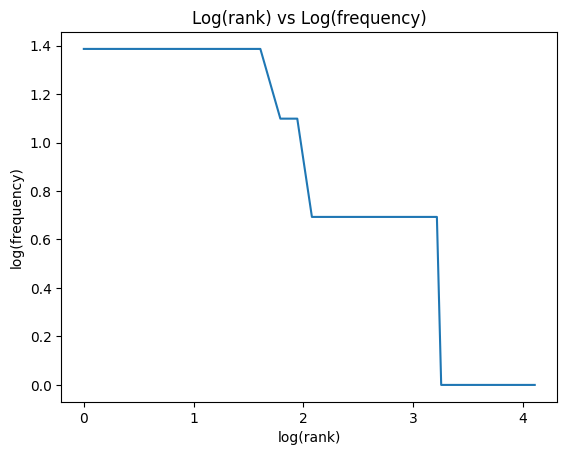


Top 5 bigrams of S1:
[(('.', 'the'), 7), (('.', 'i'), 5), (('yesterday', '.'), 4), (('has', 'stopped'), 4), (('stopped', 'syncing'), 4)]

Top 5 bigrams of S3:
[(('stopped', 'syncing'), 4), (('assignment', 'deadline'), 2), (('worked', 'yesterday'), 2), (('lms', 'stopped'), 2), (('uploading', 'file'), 2)]


In [ ]:
from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt

S1 = []
S2 = []
S3 = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)

    S1.extend(result["tokens"])
    S2.extend(result["tokens"])
    S3.extend(result["final"])

S2 = [word for word in S2 if word not in ".,!?;:"]

S4 = [porter.stem(word) for word in S3]

def statistics(data):
    total = len(data)
    unique = len(set(data))
    ttr = unique / total
    return total, unique, ttr

print("S1:", statistics(S1))
print("S2:", statistics(S2))
print("S3:", statistics(S3))
print("S4:", statistics(S4))

print("\nTop 10 words of S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

frequency = Counter(S3)
freq = sorted(frequency.values(), reverse=True)
rank = np.arange(1, len(freq) + 1)

plt.plot(np.log(rank), np.log(freq))
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs Log(frequency)")
plt.show()

print("\nTop 5 bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams of S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR increases from S1 to S4 because preprocessing removes punctuation and stopwords, reducing the total number of tokens. Although Porter stemming also combines some word forms, the reduction in total tokens is larger than the reduction in unique tokens in this dataset, so the TTR increases.